In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pathlib
import tarfile
import os

# Download dataset archive
url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

archive_path = tf.keras.utils.get_file(
    fname="flower_photos.tgz",
    origin=url
)

# Extract into a fixed directory
extract_path = "/content/flower_dataset"

os.makedirs(extract_path, exist_ok=True)

with tarfile.open(archive_path, "r:gz") as tar:
    tar.extractall(path=extract_path)

# Set the correct dataset directory
data_dir = pathlib.Path(extract_path) / "flower_photos"

print("Dataset exists:", data_dir.exists())
print("Dataset location:", data_dir)

# Count images
image_files = list(data_dir.rglob("*.jpg"))

print("Total images:", len(image_files))
print("Sample images:", image_files[:5])

# Display categories
print("Categories:", [folder.name for folder in data_dir.iterdir()
                       if folder.is_dir()])

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


/tmp/ipykernel_370/532566975.py:22: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_path)


Dataset exists: True
Dataset location: /content/flower_dataset/flower_photos
Total images: 3670
Sample images: [PosixPath('/content/flower_dataset/flower_photos/tulips/4571993204_5b3efe0e78.jpg'), PosixPath('/content/flower_dataset/flower_photos/tulips/11746276_de3dec8201.jpg'), PosixPath('/content/flower_dataset/flower_photos/tulips/8713390684_041148dd3e_n.jpg'), PosixPath('/content/flower_dataset/flower_photos/tulips/3516271083_fba63b5861.jpg'), PosixPath('/content/flower_dataset/flower_photos/tulips/3990746027_338ee436d2_n.jpg')]
Categories: ['tulips', 'sunflowers', 'daisy', 'roses', 'dandelion']


In [3]:
BATCH_SIZE = 32
IMAGE_SIZE = (224, 224)
SEED = 123

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.


In [4]:
class_names = train_ds.class_names

print("Flower categories:", class_names)
print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))

Flower categories: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Training batches: 92
Validation batches: 23


In [5]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("First five labels:", labels[:5].numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
First five labels: [2 1 4 3 1]


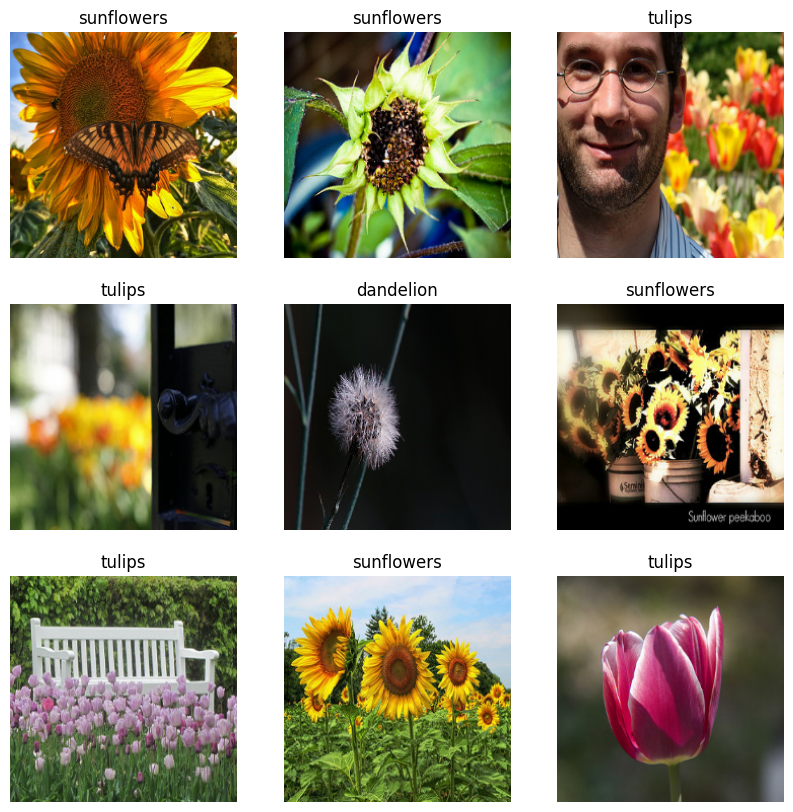

In [6]:
plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.show()

In [7]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

val_ds = val_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

In [8]:
for images, labels in train_ds.take(1):
    print("Minimum:", tf.reduce_min(images).numpy())
    print("Maximum:", tf.reduce_max(images).numpy())
    print("Shape:", images.shape)

Minimum: 0.0
Maximum: 1.0
Shape: (32, 224, 224, 3)


In [9]:
flatten_layer = tf.keras.layers.Flatten()

for images, labels in train_ds.take(1):

    first_image = images[0]

    # Add batch dimension
    first_image = tf.expand_dims(first_image, axis=0)

    flattened_image = flatten_layer(first_image)

    print("Original shape:", first_image.shape)
    print("Flattened shape:", flattened_image.shape)

Original shape: (1, 224, 224, 3)
Flattened shape: (1, 150528)


In [10]:
for images, labels in train_ds.take(1):

    flattened_batch = flatten_layer(images)

    print("Original batch:", images.shape)
    print("Flattened batch:", flattened_batch.shape)

Original batch: (32, 224, 224, 3)
Flattened batch: (32, 150528)


In [11]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(5),

    tf.keras.layers.Softmax()
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 150528)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │       752,645 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax (Softmax)               │ (None, 5)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 752,645 (2.87 MB)

 Trainable params: 752,645 (2.87 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [13]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 13s 116ms/step - accuracy: 0.3396 - loss: 11.7422 - val_accuracy: 0.4101 - val_loss: 4.9297
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 15s 77ms/step - accuracy: 0.4189 - loss: 6.7783 - val_accuracy: 0.3379 - val_loss: 8.7954
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 77ms/step - accuracy: 0.4482 - loss: 5.6720 - val_accuracy: 0.3856 - val_loss: 9.0499
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.4799 - loss: 5.8429 - val_accuracy: 0.3583 - val_loss: 6.1780
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 82ms/step - accuracy: 0.5419 - loss: 4.0198 - val_accuracy: 0.4005 - val_loss: 7.4254
Epoch 6/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 64ms/step - accuracy: 0.5283 - loss: 5.1850 - val_accuracy: 0.3079 - val_loss: 10.1997
Epoch 7/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 80ms/step - accuracy: 0.5078 - loss: 6.3958 - val_accuracy: 0.3392 - val_loss: 8.1685
Epoch 8/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 80ms/step - accuracy: 0.6073 - loss: 3.5553 - val_accuracy: 0.3

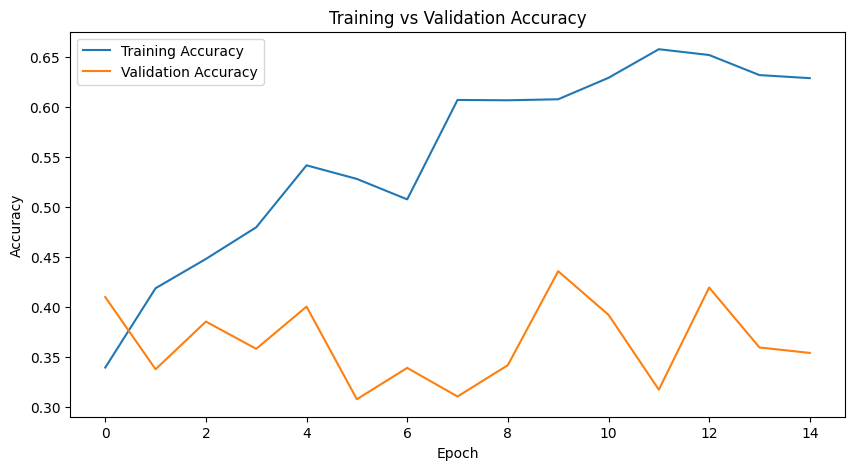

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')

plt.legend()
plt.show()

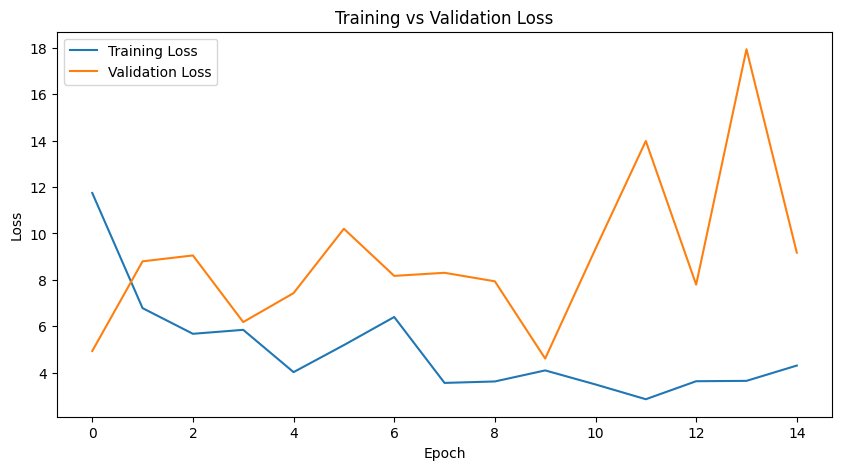

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')

plt.legend()
plt.show()

In [16]:
print("Final Training Accuracy:",
      history.history['accuracy'][-1])

print("Final Validation Accuracy:",
      history.history['val_accuracy'][-1])

print("Final Training Loss:",
      history.history['loss'][-1])

print("Final Validation Loss:",
      history.history['val_loss'][-1])

Final Training Accuracy: 0.6290872097015381
Final Validation Accuracy: 0.35422343015670776
Final Training Loss: 4.303279399871826
Final Validation Loss: 9.168975830078125


In [17]:
import numpy as np

for images, labels in val_ds.take(1):

    predictions = model.predict(images)

    for i in range(5):

        predicted_class = np.argmax(predictions[i])

        actual_class = labels[i].numpy()

        print("Actual:", class_names[actual_class])
        print("Predicted:", class_names[predicted_class])
        print("Confidence:", round(float(predictions[i][predicted_class]) * 100, 2), "%")
        print("--------------------------")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step
Actual: tulips
Predicted: tulips
Confidence: 96.69 %
--------------------------
Actual: dandelion
Predicted: daisy
Confidence: 100.0 %
--------------------------
Actual: tulips
Predicted: tulips
Confidence: 98.56 %
--------------------------
Actual: roses
Predicted: roses
Confidence: 75.66 %
--------------------------
Actual: roses
Predicted: daisy
Confidence: 100.0 %
--------------------------


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


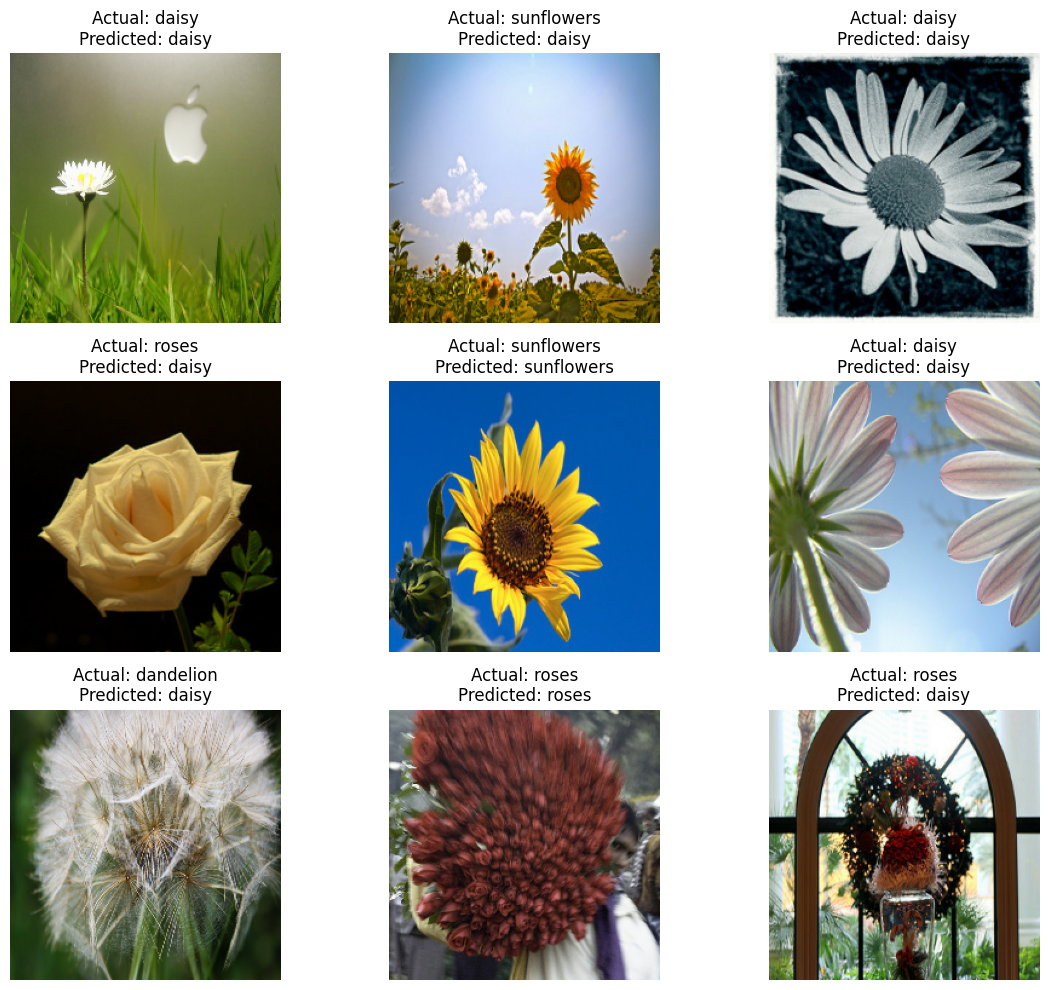

In [18]:
plt.figure(figsize=(12, 10))

for images, labels in val_ds.take(1):

    predictions = model.predict(images)

    for i in range(9):

        predicted_class = np.argmax(predictions[i])
        actual_class = labels[i].numpy()

        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy())

        plt.title(
            f"Actual: {class_names[actual_class]}\n"
            f"Predicted: {class_names[predicted_class]}"
        )

        plt.axis("off")

plt.tight_layout()
plt.show()